In [1]:
# Instalación: pip install pygmm

import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 0. CARGAR DATASET
# =======================================
# df = pd.read_csv("../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv")
df = pd.read_csv("../data_ready/COLLECT_COMP_dataset_treated.csv")
df_with_factors = pd.read_csv('../Aprendisaje/df_with_factors.csv')

In [3]:
# df['ICTHOME']
# student_variables_continuous = [col for col in df_with_factors.columns if col.startswith('ST')]

In [3]:
# PASO 1: PREPARACIÓN DE VARIABLES PARA ACL
# ==========================================

# Opción A: Usar puntuaciones factoriales del AFE
acl_variables_continuous = [col for col in df_with_factors.columns if 'Factor_' in col]
# Opción B: Usar variables categóricas originales
# Convertir a dummies si es necesario
acl_variables_manual = [
    'SCHLTYPE',      # Tipo de escuela
    'IMMIG',        # Estatus migratorio
    'REPEAT',       # Repetición de grado
    # Añade más según tu dataset
    'ST004D01T', # Genero
    'ST003D02T', # MES nacimiento
    'ST003D03T', # AÑO nacimiento
    'IMMIG', # Estatus migratorio
    'LANGN', # Lengaje en 
    # 'ESCS', # Indice socieconomico
    # 'HOMEPOS', # Pocesiones en casa
    'PAREDINT', # Educacion padres
    # Identificar todas las variables ST
]

# student_variables_continuous = [col for col in df.columns if col.startswith('ST')]
acl_variables_categorical = acl_variables_manual

# Crear dataset para ACL
# Para este ejemplo, usaremos las puntuaciones factoriales + algunas categóricas
df_acl = df_with_factors[acl_variables_continuous].copy()

# Añadir variables categóricas como dummies
for cat_var in acl_variables_categorical:
    if cat_var in df_with_factors.columns:
        dummies = pd.get_dummies(df_with_factors[cat_var], prefix=cat_var)
        df_acl = pd.concat([df_acl, dummies], axis=1)

# Eliminar missing values
df_acl = df_acl.dropna()
print(f"Variables para ACL: {df_acl.shape[1]}")
print(f"Observaciones: {df_acl.shape[0]}")

# Estandarizar variables continuas
scaler = StandardScaler()
df_acl_scaled = pd.DataFrame(
    scaler.fit_transform(df_acl),
    columns=df_acl.columns,
    index=df_acl.index
)

Variables para ACL: 49
Observaciones: 6968


In [4]:
df_acl

,Factor_1_Score,Factor_2_Score,Factor_7_Score,Factor_8_Score,Factor_9_Score,Factor_11_Score,SCHLTYPE_Private Government-dependent,SCHLTYPE_Private independent,SCHLTYPE_Public,IMMIG_First-Generation student,...,LANGN_English,LANGN_Missing,LANGN_Quechua,LANGN_Spanish,PAREDINT_3.0,PAREDINT_6.0,PAREDINT_9.0,PAREDINT_12.0,PAREDINT_14.5,PAREDINT_16.0
0,-0.493444,0.783784,1.205973,0.633266,0.685374,2.369148,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
1,0.094325,1.407910,-0.868510,0.571156,-0.291186,-0.498986,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
2,-0.236149,-0.807549,1.083039,-0.995118,0.065036,0.214088,False,False,True,False,...,False,False,False,True,False,False,True,False,False,False
3,0.077280,-0.970616,0.893987,0.034888,-1.028894,0.833396,False,False,True,False,...,False,False,False,True,True,False,False,False,False,False
4,-0.335316,0.660466,0.765561,-0.471327,0.978359,0.108292,False,True,False,False,...,False,False,False,True,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6963,0.252040,-2.300492,0.874722,0.374019,-0.788221,-1.209264,False,False,True,False,...,False,False,False,True,False,False,False,False,True,False
6964,-0.337162,-0.436094,-0.971631,-0.992547,-0.509457,-0.912271,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
6965,-0.532792,-0.324412,0.558886,0.931641,1.317473,-0.852753,False,True,False,False,...,False,False,False,True,False,False,False,False,False,True
6966,1.682772,2.070901,-1.648625,-4.378855,-1.612695,-0.715372,False,False,True,False,...,False,False,False,True,False,False,False,False,True,False



Probando 2 clases...
  BIC: -1165673.83
  AIC: -1183132.14
  Silhouette: 0.451

Probando 3 clases...
  BIC: -1164274.99
  AIC: -1190465.89
  Silhouette: 0.188

Probando 4 clases...
  BIC: -1366239.31
  AIC: -1401162.78
  Silhouette: 0.062

Probando 5 clases...
  BIC: -1472795.16
  AIC: -1516451.21
  Silhouette: 0.079

Probando 6 clases...
  BIC: -1371313.41
  AIC: -1423702.05
  Silhouette: 0.079

Probando 7 clases...
  BIC: -1456553.02
  AIC: -1517674.24
  Silhouette: 0.094

Probando 8 clases...
  BIC: -1524804.01
  AIC: -1594657.81
  Silhouette: 0.111

Probando 9 clases...
  BIC: -1638760.43
  AIC: -1717346.82
  Silhouette: 0.128


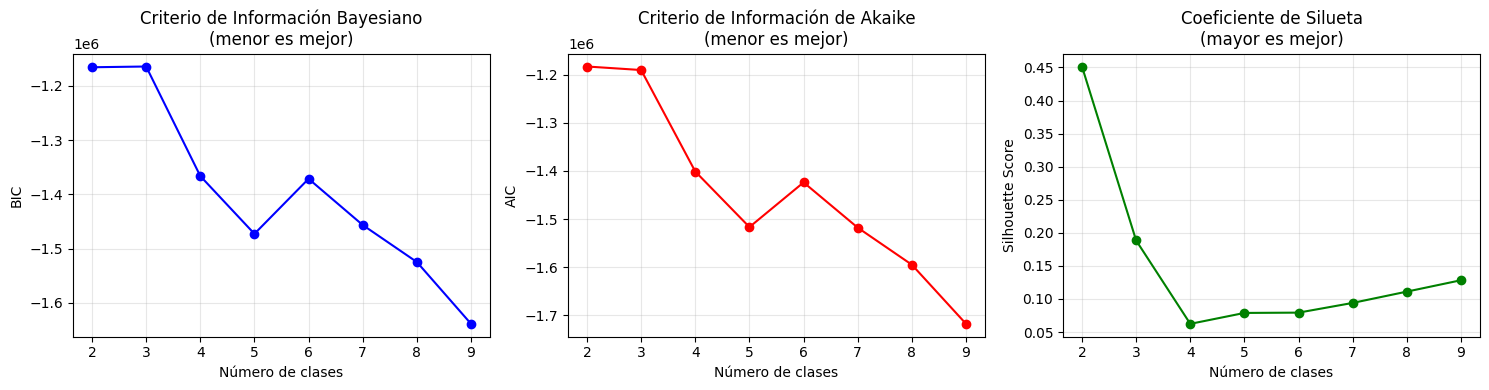

In [5]:
# PASO 2: DETERMINAR NÚMERO ÓPTIMO DE CLASES
# ===========================================

# Probar diferentes números de clases
n_classes_range = range(2, 10)
models = {}
bic_scores = []
aic_scores = []
silhouette_scores = []

from sklearn.metrics import silhouette_score

for n_classes in n_classes_range:
    print(f"\nProbando {n_classes} clases...")
    
    # Ajustar modelo
    gmm = GaussianMixture(
        n_components=n_classes,
        covariance_type='full',
        random_state=42,
        n_init=10,
        max_iter=200
    )
    gmm.fit(df_acl_scaled)
    
    # Guardar modelo
    models[n_classes] = gmm
    
    # Calcular criterios de información
    bic_scores.append(gmm.bic(df_acl_scaled))
    aic_scores.append(gmm.aic(df_acl_scaled))
    
    # Silhouette score
    labels = gmm.predict(df_acl_scaled)
    silhouette = silhouette_score(df_acl_scaled, labels)
    silhouette_scores.append(silhouette)
    
    print(f"  BIC: {bic_scores[-1]:.2f}")
    print(f"  AIC: {aic_scores[-1]:.2f}")
    print(f"  Silhouette: {silhouette:.3f}")

# Visualizar criterios
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# BIC
axes[0].plot(n_classes_range, bic_scores, 'bo-')
axes[0].set_xlabel('Número de clases')
axes[0].set_ylabel('BIC')
axes[0].set_title('Criterio de Información Bayesiano\n(menor es mejor)')
axes[0].grid(True, alpha=0.3)

# AIC
axes[1].plot(n_classes_range, aic_scores, 'ro-')
axes[1].set_xlabel('Número de clases')
axes[1].set_ylabel('AIC')
axes[1].set_title('Criterio de Información de Akaike\n(menor es mejor)')
axes[1].grid(True, alpha=0.3)

# Silhouette
axes[2].plot(n_classes_range, silhouette_scores, 'go-')
axes[2].set_xlabel('Número de clases')
axes[2].set_ylabel('Silhouette Score')
axes[2].set_title('Coeficiente de Silueta\n(mayor es mejor)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# PASO 3: SELECCIONAR NÚMERO ÓPTIMO DE CLASES
# ============================================

# Encontrar el óptimo basado en BIC (mínimo)
optimal_n_bic = n_classes_range[np.argmin(bic_scores)]
print(f"\nNúmero óptimo de clases según BIC: {optimal_n_bic}")

# Encontrar el óptimo basado en AIC
optimal_n_aic = n_classes_range[np.argmin(aic_scores)]
print(f"Número óptimo de clases según AIC: {optimal_n_aic}")

# Decisión final (puedes ajustar basado en interpretabilidad)
n_classes_final = optimal_n_bic  # o ajusta manualmente


Número óptimo de clases según BIC: 9
Número óptimo de clases según AIC: 9


In [7]:
# PASO 4: AJUSTAR MODELO FINAL
# =============================

gmm_final = models[n_classes_final]
class_labels = gmm_final.predict(df_acl_scaled)
class_probabilities = gmm_final.predict_proba(df_acl_scaled)

# Añadir clases al dataset
df_with_classes = df_with_factors.copy()
df_with_classes.loc[df_acl.index, 'latent_class'] = class_labels

# Calcular entropía (medida de certeza en la clasificación)
entropy = 1 + np.sum(class_probabilities * np.log(class_probabilities + 1e-10)) / (len(df_acl) * np.log(n_classes_final))
print(f"\nEntropía del modelo: {entropy:.3f}")
print("(Valores cercanos a 1 indican buena separación entre clases)")


Entropía del modelo: 1.000
(Valores cercanos a 1 indican buena separación entre clases)



PERFILES DE CLASES LATENTES

Distribución de clases:
  Clase 0: 529 estudiantes (7.6%)
  Clase 1: 574 estudiantes (8.2%)
  Clase 2: 559 estudiantes (8.0%)
  Clase 3: 1678 estudiantes (24.1%)
  Clase 4: 2274 estudiantes (32.6%)
  Clase 5: 506 estudiantes (7.3%)
  Clase 6: 156 estudiantes (2.2%)
  Clase 7: 630 estudiantes (9.0%)
  Clase 8: 62 estudiantes (0.9%)

Factor_1_Score:
  Clase 0: μ=-0.05 (σ=0.97)
  Clase 1: μ=-0.01 (σ=1.05)
  Clase 2: μ=-0.01 (σ=0.97)
  Clase 3: μ=0.02 (σ=1.01)
  Clase 4: μ=0.01 (σ=1.01)
  Clase 5: μ=-0.05 (σ=1.00)
  Clase 6: μ=-0.21 (σ=0.66)
  Clase 7: μ=0.06 (σ=0.97)
  Clase 8: μ=0.10 (σ=1.13)

Factor_2_Score:
  Clase 0: μ=-0.01 (σ=1.04)
  Clase 1: μ=-0.00 (σ=0.99)
  Clase 2: μ=-0.01 (σ=0.97)
  Clase 3: μ=-0.02 (σ=1.02)
  Clase 4: μ=0.02 (σ=0.98)
  Clase 5: μ=-0.01 (σ=1.02)
  Clase 6: μ=-0.00 (σ=1.03)
  Clase 7: μ=-0.01 (σ=0.99)
  Clase 8: μ=-0.00 (σ=1.12)

Factor_7_Score:
  Clase 0: μ=-0.01 (σ=1.03)
  Clase 1: μ=-0.01 (σ=0.96)
  Clase 2: μ=-0.02 (σ=1.05)
  C

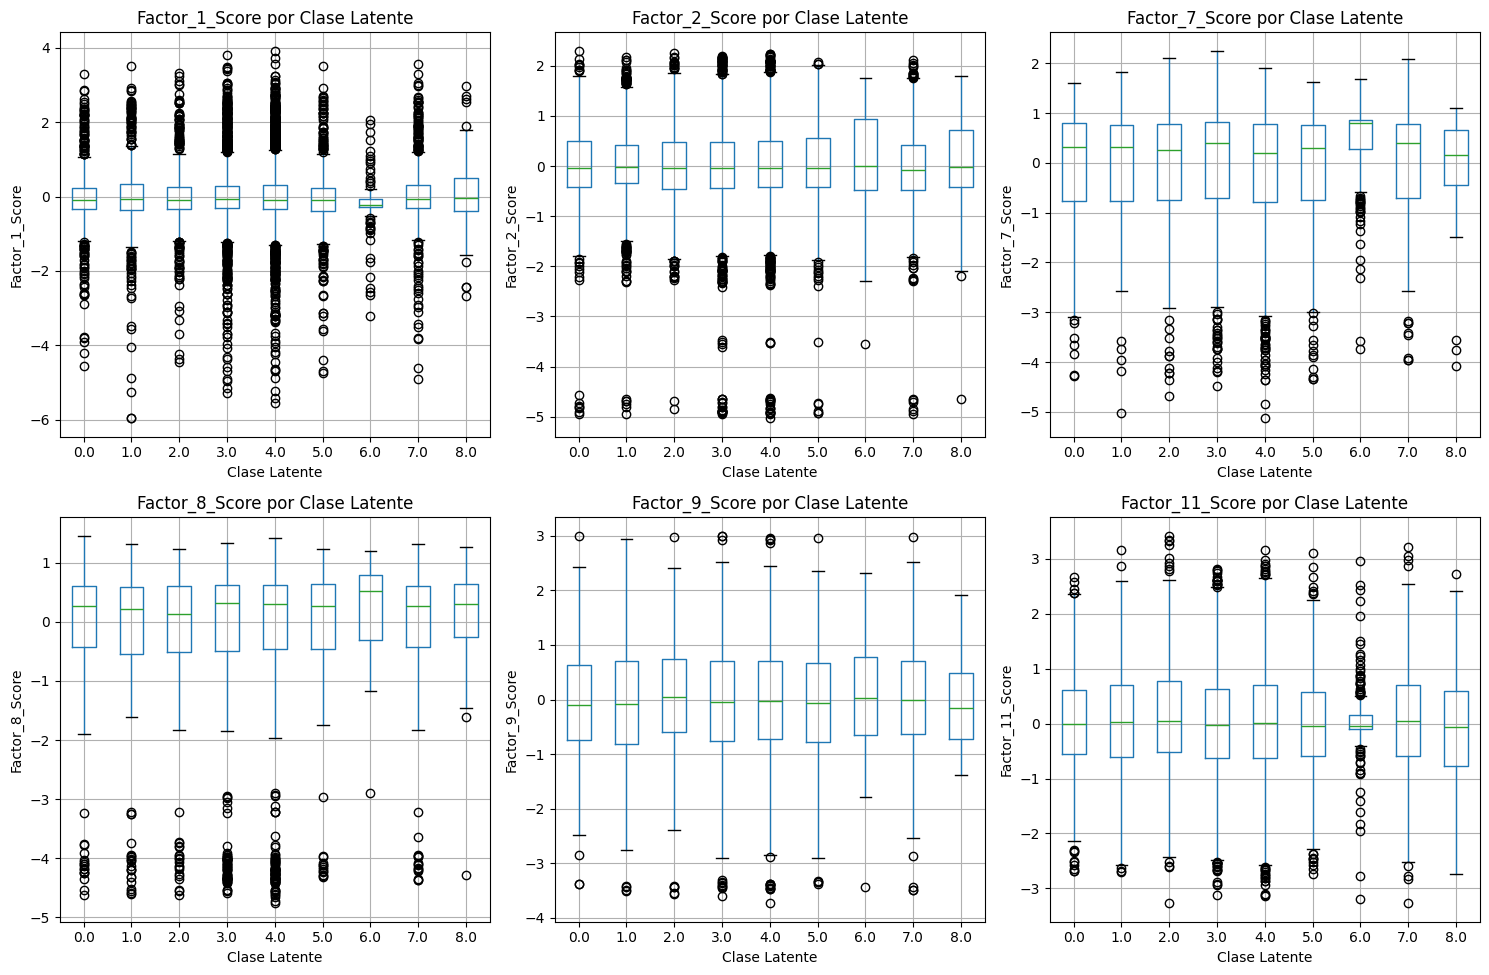

In [8]:
# PASO 5: PERFILAR LAS CLASES
# ============================

print(f"\n{'='*60}")
print("PERFILES DE CLASES LATENTES")
print(f"{'='*60}")

# Tamaño de cada clase
class_sizes = pd.Series(class_labels).value_counts().sort_index()
print("\nDistribución de clases:")
for i, size in class_sizes.items():
    pct = (size / len(class_labels)) * 100
    print(f"  Clase {i}: {size} estudiantes ({pct:.1f}%)")

# Caracterización por variables originales
profile_vars = acl_variables_continuous + ['PV1MATH', 'PV1READ', 'PV1SCIE']  # Añade rendimiento

for var in profile_vars:
    if var in df_with_classes.columns:
        print(f"\n{var}:")
        means = df_with_classes.groupby('latent_class')[var].mean()
        stds = df_with_classes.groupby('latent_class')[var].std()
        
        for clase in range(n_classes_final):
            print(f"  Clase {clase}: μ={means[clase]:.2f} (σ={stds[clase]:.2f})")

# Visualización de perfiles
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, var in enumerate(profile_vars[:6]):  # Primeras 6 variables
    if var in df_with_classes.columns:
        df_with_classes.boxplot(column=var, by='latent_class', ax=axes[idx])
        axes[idx].set_title(f'{var} por Clase Latente')
        axes[idx].set_xlabel('Clase Latente')
        axes[idx].set_ylabel(var)

plt.suptitle('')
plt.tight_layout()
plt.show()

In [9]:
# PASO 6: VALIDACIÓN DE LA SOLUCIÓN
# ==================================

# 6.1 Análisis discriminante para validar clases
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score

# Preparar datos
X_validation = df_acl_scaled
y_validation = class_labels

# LDA con validación cruzada
lda = LinearDiscriminantAnalysis()
scores = cross_val_score(lda, X_validation, y_validation, cv=5)
print(f"\nValidación de clases (LDA):")
print(f"Precisión promedio: {scores.mean():.3f} (+/- {scores.std():.3f})")
print("(Valores > 0.8 indican buena separación)")

# 6.2 ANOVA para diferencias entre clases
from scipy import stats

print("\nANOVA - Diferencias significativas entre clases:")
for var in profile_vars:
    if var in df_with_classes.columns:
        groups = [group[var].dropna() for name, group in df_with_classes.groupby('latent_class')]
        f_stat, p_value = stats.f_oneway(*groups)
        print(f"  {var}: F={f_stat:.2f}, p={p_value:.4e}", end="")
        if p_value < 0.001:
            print(" ***")
        elif p_value < 0.01:
            print(" **")
        elif p_value < 0.05:
            print(" *")
        else:
            print(" (n.s.)")


Validación de clases (LDA):
Precisión promedio: 0.136 (+/- 0.100)
(Valores > 0.8 indican buena separación)

ANOVA - Diferencias significativas entre clases:
  Factor_1_Score: F=1.63, p=1.0967e-01 (n.s.)
  Factor_2_Score: F=0.22, p=9.8668e-01 (n.s.)
  Factor_7_Score: F=5.24, p=1.4887e-06 ***
  Factor_8_Score: F=1.50, p=1.5164e-01 (n.s.)
  Factor_9_Score: F=0.77, p=6.3353e-01 (n.s.)
  Factor_11_Score: F=1.07, p=3.8176e-01 (n.s.)
  PV1MATH: F=10.14, p=3.6073e-14 ***
  PV1READ: F=10.94, p=1.8944e-15 ***
  PV1SCIE: F=11.89, p=5.5981e-17 ***


In [10]:
# PASO 7: INTERPRETACIÓN Y ETIQUETADO
# ====================================

# Crear resumen interpretativo
print(f"\n{'='*60}")
print("INTERPRETACIÓN SUGERIDA DE CLASES")
print(f"{'='*60}")

# Analizar características distintivas de cada clase
for clase in range(n_classes_final):
    print(f"\nCLASE {clase}:")
    clase_data = df_with_classes[df_with_classes['latent_class'] == clase]
    
    # Rendimiento promedio
    if 'PV1MATH' in clase_data.columns:
        math_mean = clase_data['PV1MATH'].mean()
        print(f"  Rendimiento matemático: {math_mean:.1f}")
    
    # Factores promedio
    for col in acl_variables_continuous:
        if col in clase_data.columns:
            factor_mean = clase_data[col].mean()
            # Interpretar como alto/medio/bajo
            if factor_mean > 0.5:
                nivel = "Alto"
            elif factor_mean < -0.5:
                nivel = "Bajo"
            else:
                nivel = "Medio"
            print(f"  {col}: {nivel} ({factor_mean:.2f})")
    
    # Sugerencia de etiqueta
    print(f"  Etiqueta sugerida: [Analizar basado en patrones]")

# Guardar resultados
df_with_classes['latent_class_prob_max'] = class_probabilities.max(axis=1)
print(f"\nResultados guardados. Dataset actualizado con {n_classes_final} clases latentes.")


INTERPRETACIÓN SUGERIDA DE CLASES

CLASE 0:
  Rendimiento matemático: 389.2
  Factor_1_Score: Medio (-0.05)
  Factor_2_Score: Medio (-0.01)
  Factor_7_Score: Medio (-0.01)
  Factor_8_Score: Medio (-0.00)
  Factor_9_Score: Medio (-0.03)
  Factor_11_Score: Medio (0.01)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 1:
  Rendimiento matemático: 397.1
  Factor_1_Score: Medio (-0.01)
  Factor_2_Score: Medio (-0.00)
  Factor_7_Score: Medio (-0.01)
  Factor_8_Score: Medio (-0.06)
  Factor_9_Score: Medio (-0.04)
  Factor_11_Score: Medio (-0.00)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 2:
  Rendimiento matemático: 392.3
  Factor_1_Score: Medio (-0.01)
  Factor_2_Score: Medio (-0.01)
  Factor_7_Score: Medio (-0.02)
  Factor_8_Score: Medio (-0.03)
  Factor_9_Score: Medio (0.05)
  Factor_11_Score: Medio (0.09)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 3:
  Rendimiento matemático: 394.5
  Factor_1_Score: Medio (0.02)
  Factor_2_Score: Medio (-0.02)
  Fac

In [12]:
df_with_classes

,CNTSCHID,CNTSTUID,STRATUM,BOOKID,RDESIGN,RCORE_TEST,RCORE_PERF,RS1_LEV,RS1_TEST,RCO1S_PERF,...,PV10SCIC,VER_DAT,Factor_1_Score,Factor_2_Score,Factor_7_Score,Factor_8_Score,Factor_9_Score,Factor_11_Score,latent_class,latent_class_prob_max
0,60400034.0,60400002.0,PER01,Form 5,Design A (Stage1 then Stage2),Testlet 1,Low Level,Low,Testlet 14,Low Level,...,364.602,02MAY23:13:48:32,-0.493444,0.783784,1.205973,0.633266,0.685374,2.369148,0.0,1.0
1,60400267.0,60400006.0,PER02,Form 15,Not used,Not used,Not used,Not used,Not used,Not used,...,358.010,02MAY23:13:48:33,0.094325,1.407910,-0.868510,0.571156,-0.291186,-0.498986,1.0,1.0
2,60400224.0,60400008.0,PER01,Form 43,Not used,Not used,Not used,Not used,Not used,Not used,...,315.926,02MAY23:13:48:32,-0.236149,-0.807549,1.083039,-0.995118,0.065036,0.214088,1.0,1.0
3,60400187.0,60400010.0,PER02,Form 4,Design A (Stage1 then Stage2),Testlet 1,Medium Level,Low,Testlet 14,Low Level,...,372.093,02MAY23:13:48:33,0.077280,-0.970616,0.893987,0.034888,-1.028894,0.833396,2.0,1.0
4,60400102.0,60400011.0,PER03,Form 24,Not used,Not used,Not used,Not used,Not used,Not used,...,400.626,02MAY23:13:48:33,-0.335316,0.660466,0.765561,-0.471327,0.978359,0.108292,4.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6963,60400176.0,60409527.0,PER01,Form 44,Not used,Not used,Not used,Not used,Not used,Not used,...,463.055,02MAY23:13:48:32,0.252040,-2.300492,0.874722,0.374019,-0.788221,-1.209264,3.0,1.0
6964,60400010.0,60409529.0,PER02,Form 9,Design A (Stage1 then Stage2),Testlet 3,Medium Level,High,Testlet 13,Low Level,...,362.291,02MAY23:13:48:33,-0.337162,-0.436094,-0.971631,-0.992547,-0.509457,-0.912271,3.0,1.0
6965,60400277.0,60409531.0,PER03,Form 8,Design B (Stage2 then Stage1),Testlet 5,Medium Level,High,Testlet 12,Medium Level,...,493.333,02MAY23:13:48:34,-0.532792,-0.324412,0.558886,0.931641,1.317473,-0.852753,4.0,1.0
6966,60400177.0,60409533.0,PER02,Form 22,Not used,Not used,Not used,Not used,Not used,Not used,...,420.300,02MAY23:13:48:33,1.682772,2.070901,-1.648625,-4.378855,-1.612695,-0.715372,1.0,1.0


In [20]:
# PASO 6.5: CREACION DE NUEVO DATASET CON VARIABLES UPDATEADAS Y REDUCIDAS
# ===========================================

# GENERAR ARCHIVO PARA ANALISIS DE CLASES LATENTES
df_with_classes.to_csv("df_with_classes.csv", index=False)
df_acl_scaled.to_csv("df_acl_scaled.csv", index=False)